In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

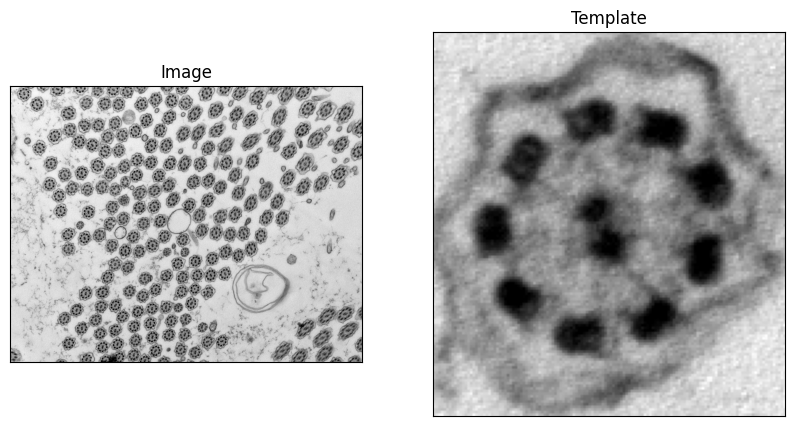

In [2]:
# Load image and template
file = 'images/Riasinky/Tv6.png'
img_bgr = cv.imread(file)
template_bgr = img_bgr[1404:1550, 655:789]

# Plot images
plt.figure(figsize=(10, 10))
plt.subplot(121), plt.imshow(img_bgr[:, :, ::-1])
plt.title('Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(template_bgr[:, :, ::-1])
plt.title('Template'), plt.xticks([]), plt.yticks([])
plt.show()

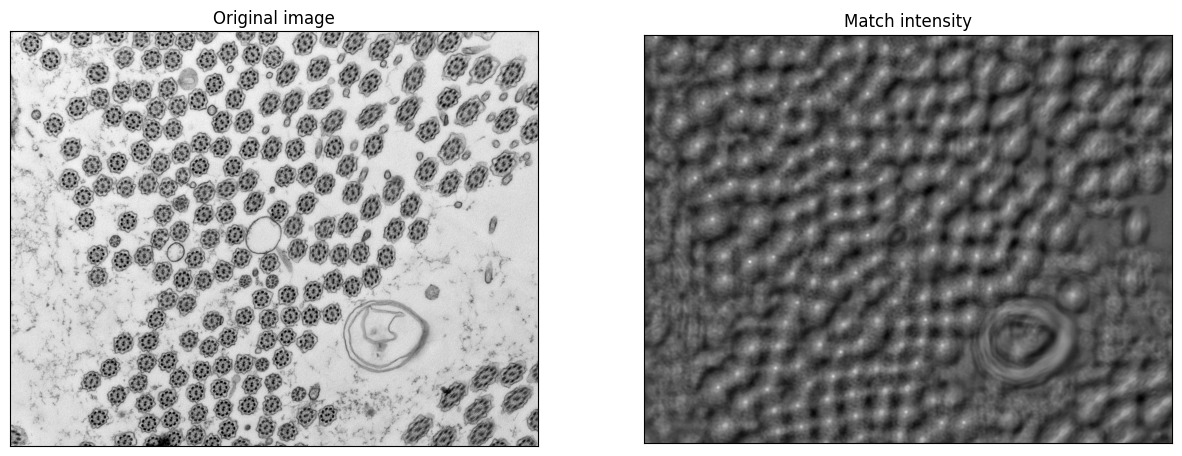

In [3]:
# Convert to grayscale
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
template = cv.cvtColor(template_bgr, cv.COLOR_BGR2GRAY)

w, h = template.shape[:2]

methods = [cv.TM_CCOEFF, cv.TM_CCOEFF_NORMED, cv.TM_CCORR, cv.TM_CCORR_NORMED, cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]

# Apply template Matching
res = cv.matchTemplate(img_gray, template, cv.TM_CCOEFF_NORMED)

# Plot images
plt.figure(figsize=(15, 15))
plt.subplot(121), plt.imshow(img_gray, cmap='gray')
plt.title('Original image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(res, cmap='gray')
plt.title('Match intensity'), plt.xticks([]), plt.yticks([])
plt.show()

Number of detected templates: 68194


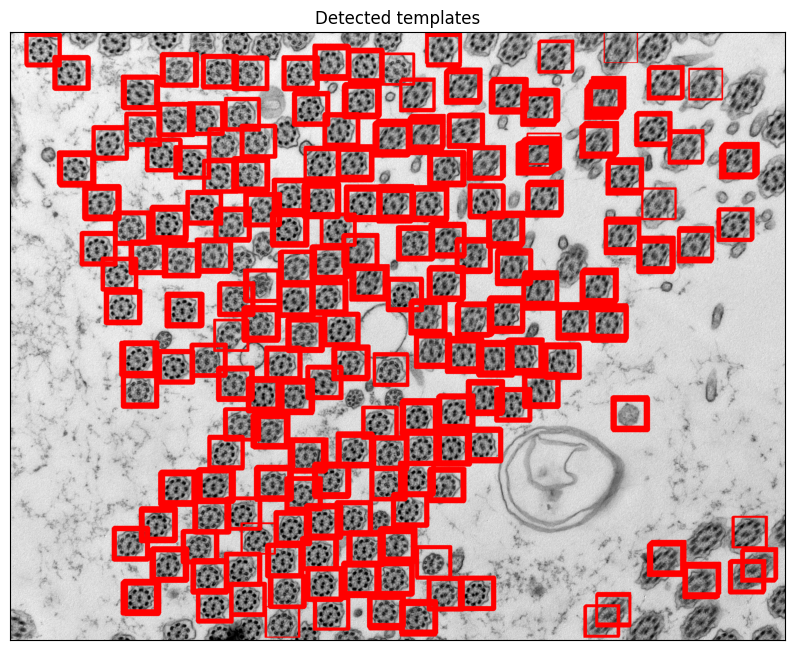

In [24]:
# get all the locations from the thresholded image
threshold = 0.45
y_coords, x_coords = np.where(res >= threshold)
rects = np.array([[x, y, x + w, y + h] for (x, y) in zip(x_coords, y_coords)])
print(f'Number of detected templates: {len(rects)}')

# draw the rectangles
img2 = img_bgr.copy()
for (x1, y1, x2, y2) in rects:
    cv.rectangle(img2, (x1, y1), (x2, y2), (0, 0, 255), 2)

# draw the rectangles
plt.figure(figsize=(10, 10))
plt.imshow(img2[:, :, ::-1])
plt.title('Detected templates'), plt.xticks([]), plt.yticks([])
plt.show()

Number of detected templates: 178


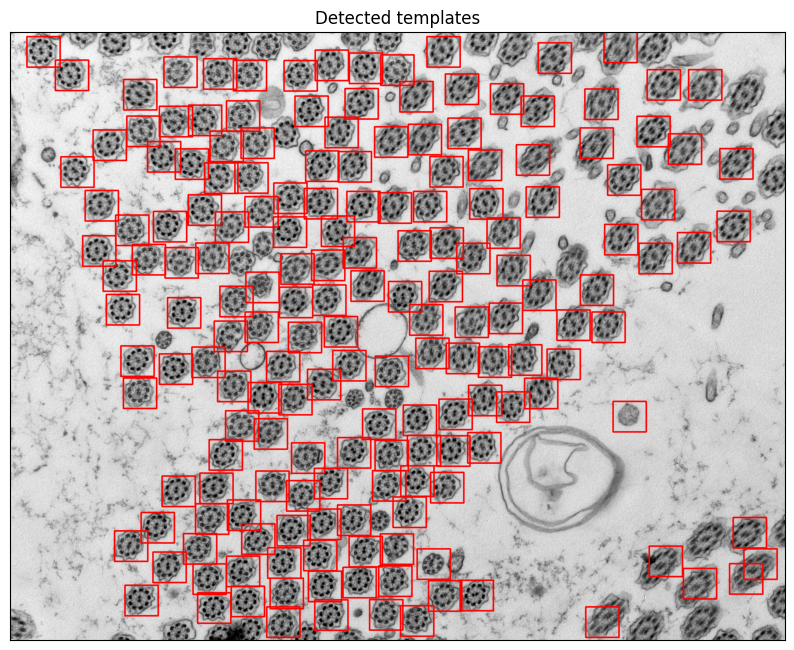

In [31]:
from imutils.object_detection import non_max_suppression

# non-maximum suppression
good_rects = non_max_suppression(rects, probs=None, overlapThresh=0.3)

print(f'Number of detected templates: {len(good_rects)}')

# draw the rectangles
img2 = img_bgr.copy()
for (x1, y1, x2, y2) in good_rects:
    cv.rectangle(img2, (x1, y1), (x2, y2), (0, 0, 255), 5)

# Plot image
plt.figure(figsize=(10, 10))
plt.imshow(img2[:, :, ::-1])
plt.title('Detected templates'), plt.xticks([]), plt.yticks([])
plt.show()